# Steering tests
Effects of the mean-vector intervention of notebook 3 (bin means, the residue's own angle): the change of log p of the original amino acid at the masked residue, against the unedited pass.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display
import torch
from transformers import AutoTokenizer, EsmForMaskedLM

from biomanifolds import config
from biomanifolds.datasets import swissprot

MODEL = "facebook/esm2_t30_150M_UR50D"
AA = "ACDEFGHIKLMNPQRSTVWY"
RESULTS = config.data_path("steering") / "nb03"
WINDOW = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = EsmForMaskedLM.from_pretrained(MODEL, attn_implementation="sdpa").eval().to(device)

results = pl.read_parquet(RESULTS / "results.parquet")
LAYERS = json.loads((RESULTS / "metadata.json").read_text())["layers"]

# effect of the mean-vector intervention, per residue and layer
unedited = results.filter(pl.col("edit") == "none").select("accession", "i", "layer", ll_unedited="log_likelihood", top1_unedited="top1_aa")
effects = (
    results.filter(pl.col("edit") == "bin_means")
    .join(unedited, on=["accession", "i", "layer"])
    .with_columns(delta_ll=pl.col("log_likelihood") - pl.col("ll_unedited"))
    .select("accession", "i", "aa", "helix_face", "layer", "delta_ll", "ll_unedited", "log_likelihood", "top1_unedited", "top1_aa")
)
effects.sort("delta_ll")[:10]

(null): No such file or directory


(null): No such file or directory


Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa
str,i64,str,f64,i64,f64,f64,f64,str,str
"""B9DMF3""",259,"""E""",154.615997,30,-1.805278,-5.326416,-7.131693,"""V""","""V"""
"""Q8FT23""",762,"""E""",-167.602402,30,-1.765963,-3.93293,-5.698894,"""L""","""L"""
"""Q9X1V8""",597,"""E""",-177.745193,30,-1.74818,-3.143819,-4.891998,"""T""","""L"""
"""Q0TAL1""",99,"""D""",137.044571,30,-1.597001,-4.596757,-6.193758,"""L""","""L"""
"""Q9QXQ0""",353,"""E""",-156.014923,30,-1.264019,-4.109928,-5.373947,"""I""","""I"""
"""P0AFF4""",222,"""E""",-138.422821,30,-1.228705,-5.540622,-6.769327,"""P""","""A"""
"""A9BNJ8""",26,"""R""",-156.055527,30,-1.19991,-5.037351,-6.237261,"""L""","""L"""
"""Q8PTN6""",41,"""R""",152.636368,30,-1.176759,-4.444025,-5.620784,"""A""","""L"""
"""O34636""",200,"""K""",139.380844,30,-1.168667,-3.928406,-5.097073,"""L""","""L"""


## Distribution of the effects

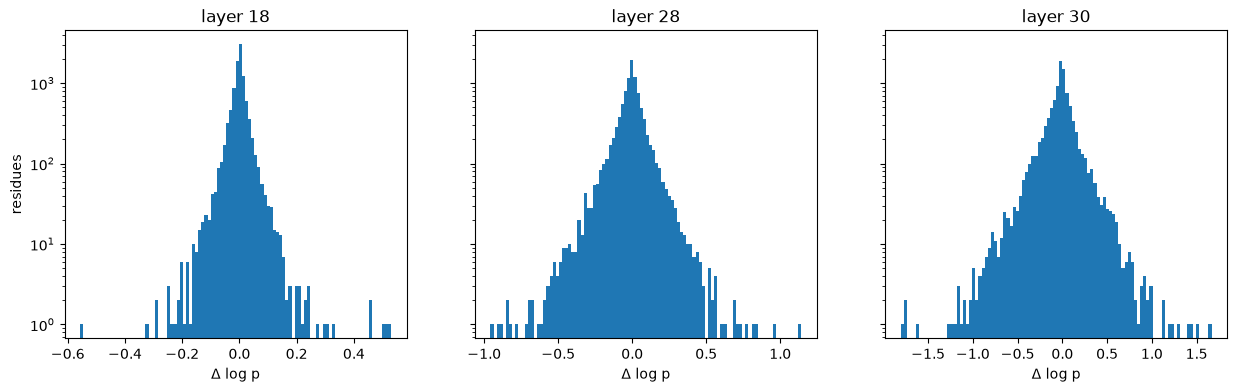

In [2]:
fig, axes = plt.subplots(1, len(LAYERS), figsize=(15, 4), sharey=True)
for ax, layer in zip(axes, LAYERS):
    ax.hist(effects.filter(pl.col("layer") == layer)["delta_ll"], bins=100)
    ax.set_yscale("log")
    ax.set_title(f"layer {layer}")
    ax.set_xlabel("Δ log p")
axes[0].set_ylabel("residues")
plt.show()

In [3]:
# Mean-vector edits that turned a correct top-1 prediction into a wrong one: the 10 largest drops of log p per layer
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])


def context(sequence, i):
    """The sequence around position i, with the masked residue in brackets."""
    return f"{sequence[max(0, i - WINDOW):i]}[{sequence[i]}]{sequence[i + 1:i + 1 + WINDOW]}"


correct_to_wrong = effects.filter((pl.col("top1_unedited") == pl.col("aa")) & (pl.col("top1_aa") != pl.col("aa")))
wrong_to_correct = effects.filter((pl.col("top1_unedited") != pl.col("aa")) & (pl.col("top1_aa") == pl.col("aa")))
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(30)
for layer in LAYERS:
    flips = correct_to_wrong.filter(pl.col("layer") == layer)
    print(f"layer {layer}: {len(flips)} correct -> wrong, {len(wrong_to_correct.filter(pl.col('layer') == layer))} wrong -> correct")
    display(
        flips.sort("delta_ll").head(20)
        .join(sequences, on="accession", maintain_order="left")
        .with_columns(context=pl.struct("sequence", "i").map_elements(lambda r: context(r["sequence"], r["i"]), return_dtype=pl.String))
        .drop("sequence")
    )


layer 18: 45 correct -> wrong, 43 wrong -> correct


accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa,context
str,i64,str,f64,i64,f64,f64,f64,str,str,str
"""Q70Y22""",274,"""A""",148.695602,18,-0.213961,-1.059147,-1.273108,"""A""","""W""","""LLTVTFLWVR[A]SYPRFRYDQL"""
"""Q0I284""",55,"""V""",154.48555,18,-0.208674,-0.545259,-0.753933,"""V""","""I""","""APTITKDGVS[V]AREIELEDKF"""
"""A1K828""",55,"""V""",152.900528,18,-0.207571,-0.517171,-0.724742,"""V""","""I""","""APTVTKDGVS[V]AKEIELKDKF"""
"""Q9NUN5""",311,"""F""",-14.389149,18,-0.148086,-1.016595,-1.16468,"""F""","""L""","""RPLKIVWGIF[F]ILVALLFVIS"""
"""Q37683""",409,"""L""",-118.609749,18,-0.143842,-1.095508,-1.239351,"""L""","""V""","""NEKKDRITDA[L]CSTRAAVQEG"""
"""Q57HW6""",73,"""A""",40.69899,18,-0.136302,-2.051039,-2.187341,"""A""","""H""","""DAQFEVVHSL[A]KWKRQTLGQH"""
"""Q0IHQ3""",275,"""W""",128.936142,18,-0.132734,-1.149812,-1.282545,"""W""","""F""","""PFVLVVAGLA[W]IVTIILLVLG"""
"""P9WML9""",49,"""T""",143.338882,18,-0.127213,-1.630672,-1.757885,"""T""","""A""","""TGVPFYDHML[T]ALGSHASFDL"""
"""P18695""",422,"""A""",-22.077971,18,-0.124134,-0.636621,-0.760755,"""A""","""S""","""FQDGLDEFDE[A]RAVVMDLVGE"""


layer 28: 117 correct -> wrong, 114 wrong -> correct


accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa,context
str,i64,str,f64,i64,f64,f64,f64,str,str,str
"""B5BHT3""",84,"""L""",-24.599018,28,-0.667945,-0.733268,-1.401213,"""L""","""C""","""VGYDNVEVDA[L]TARKIVLMHT"""
"""Q8K4X7""",101,"""F""",-14.241621,28,-0.557167,-0.662803,-1.21997,"""F""","""W""","""VVLNHKFEID[F]LCGWSLAERL"""
"""P38680""",278,"""L""",-41.982677,28,-0.554246,-1.269271,-1.823517,"""L""","""A""","""PSDYKKSIVA[L]GLIEIFIYTV"""
"""P06358""",104,"""I""",-32.499512,28,-0.447007,-0.650099,-1.097106,"""I""","""R""","""IIFRLGMAPT[I]PGARQLVNHR"""
"""B8J189""",99,"""A""",-175.56749,28,-0.433141,-1.363113,-1.796254,"""A""","""I""","""QPHSGSQANM[A]AYLAVLKPGD"""
"""B9KBJ6""",77,"""E""",169.945862,28,-0.424046,-1.508328,-1.932374,"""E""","""A""","""NKVQVIKVVR[E]ITGLGLKEAK"""
"""Q7U7P8""",17,"""L""",-3.183306,28,-0.355595,-1.654821,-2.010416,"""L""","""A""","""DWTIAEIQAL[L]ELPLMELLWQ"""
"""P36859""",793,"""Y""",-172.576401,28,-0.345811,-0.816128,-1.16194,"""Y""","""L""","""LAGGTGITPV[Y]QVMQAILKDP"""
"""Q3AJW5""",311,"""E""",-179.674179,28,-0.341013,-1.853776,-2.194789,"""E""","""A""","""EPGLILQRVI[E]EHYSQVDSVE"""


layer 30: 212 correct -> wrong, 178 wrong -> correct


accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa,context
str,i64,str,f64,i64,f64,f64,f64,str,str,str
"""A2RL76""",574,"""L""",-15.342299,30,-0.73327,-0.785805,-1.519075,"""L""","""K""","""GGDISRKRKL[L]EKQKAGKKRM"""
"""B8E1C0""",262,"""V""",-4.426413,30,-0.72327,-1.663636,-2.386905,"""V""","""K""","""EELFKTVLKE[V]MNIEINTPFP"""
"""Q8L707""",186,"""L""",20.838463,30,-0.661835,-1.399245,-2.06108,"""L""","""R""","""HLTGVMHSLM[L]VPYDLVWIVV"""
"""B9KBJ6""",77,"""E""",169.945862,30,-0.645709,-1.508328,-2.154037,"""E""","""A""","""NKVQVIKVVR[E]ITGLGLKEAK"""
"""Q02ND5""",325,"""V""",20.71039,30,-0.631939,-1.818238,-2.450177,"""V""","""K""","""LINLLVTGAL[V]LAAAQ"""
"""Q7U7P8""",17,"""L""",-3.183306,30,-0.628546,-1.654822,-2.283367,"""L""","""R""","""DWTIAEIQAL[L]ELPLMELLWQ"""
"""C3KBZ7""",496,"""L""",-16.738131,30,-0.612296,-1.357161,-1.969456,"""L""","""A""","""VIFLKPVLPL[L]AADAEAFLNV"""
"""Q3AJW5""",311,"""E""",-179.674179,30,-0.60596,-1.853776,-2.459736,"""E""","""A""","""EPGLILQRVI[E]EHYSQVDSVE"""
"""P06358""",104,"""I""",-32.499512,30,-0.539225,-0.6501,-1.189325,"""I""","""R""","""IIFRLGMAPT[I]PGARQLVNHR"""


## Is the helix face angle representation being used to predict hydrophobic vs. hydrophilic residues ?

### Hydrophobicity and helix face as binary labels
Residues along an alpha helix tend to be hydrophobic if facing the core of the protein, and hydrophilic if facing the opposite direction [Eisenberg et al., 1982](https://www.nature.com/articles/299371a0). By definition, helix face angle is 0 degrees when pointing towards the centroid of the protein, and 180 degrees when opposite to it.
- The Eisenberg consensus scale [Eisenberg et al., 1984](https://pubmed.ncbi.nlm.nih.gov/6502707/) gives positive values to hydrophobic amino-acids, and negative values to hydrophilic aminoacids. We'll use it to classify residues as one or the other
- A simple approach we can take, is to divide helix face angles into an "inner" and an "outer" face, for angle absolute values $|\theta|$ below or above 90 degrees, respectively. 

Let $H(x_i) \in \{0, 1\}$ be whether the residue $x_i$ is hydrophobic, and $F_i \in \{0, 1\}$ whether the $i^{th}$ residue's position is in the inner face, meaning $|\theta| \leq 90$. We have $H(x_i) = F_i$ when there is agreement between the residue's face and hydrophobicity, otherwise $H(x_i) \neq F_i$. Two outcomes can be measured:
- Let $x_i^{dec}$ be the **decoded** residue, meaning the residue with the highest probability as predicted by the PLM. We can measure the change in rate of top-predicted residues where $H(x_i^{dec}) = F_i$, before and after intervention: $\Delta P(H(x_i^{dec}) = F_i)$. 
- Effect on the model's total probability mass attributed to hydrophobic residues, conditioned on residue face: $\Delta P_{PLM}(H = F)$ .

In [4]:
HYDROPHOBIC, HYDROPHILIC = "ACGILMFPWYV", "STNQHDEKR"  # sign of the Eisenberg consensus scale
EDITS = [method + control for method in ["bin_means", "linear", "harmonic"]  # the three approximations of the latent (notebook 3)
         for control in ["", " | random angle", " | random vector"]]
METRICS = ["decoded_residue_agrees_with_face", "probability_mass_agrees_with_face"]
N_BOOT = 2000
boot_rng = np.random.default_rng(1)

# per row: does the decoded residue's class agree with the face, and the probability mass on the class that agrees with it
probs = np.exp(np.array(results["aa_log_probs"].to_list()))  # (rows, 20), amino acids in the order of AA
in_hydrophobic = np.array([a in HYDROPHOBIC for a in AA])
inner_face = (results["helix_face"].abs() <= 90).to_numpy()  # F_i: inner face, |theta| <= 90 degrees
m = results.with_columns(
    inner_face=pl.Series(inner_face),
    decoded_residue_agrees_with_face=(pl.col("top1_aa").is_in(list(HYDROPHOBIC)) == pl.Series(inner_face)).cast(pl.Float64),
    probability_mass_agrees_with_face=np.where(inner_face, probs[:, in_hydrophobic].sum(1), probs[:, ~in_hydrophobic].sum(1)),
    true_residue_agrees_with_face=(pl.col("aa").is_in(list(HYDROPHOBIC)) == pl.Series(inner_face)).cast(pl.Float64),
)
before = m.filter(pl.col("edit") == "none").select("accession", "i", "layer", *[pl.col(x).alias(f"{x} before") for x in METRICS])
changes = (
    m.filter(pl.col("edit").is_in(EDITS))
    .join(before, on=["accession", "i", "layer"])
    .with_columns(*[(pl.col(x) - pl.col(f"{x} before")).alias(f"{x} change") for x in METRICS])
)

# bootstrap: resampling proteins
proteins = results["accession"].unique().sort()
weights = boot_rng.multinomial(len(proteins), np.full(len(proteins), 1 / len(proteins)), size=N_BOOT)  # (N_BOOT, proteins)


def mean_and_boot(frame, column):
    """Mean of `column` over residues, and its bootstrap values (resampling proteins)."""
    per_protein = pl.DataFrame({"accession": proteins}).join(
        frame.group_by("accession").agg(s=pl.col(column).sum(), n=pl.len()), on="accession", how="left").fill_null(0)
    s, n = per_protein["s"].to_numpy(), per_protein["n"].to_numpy()
    return s.sum() / n.sum(), (weights @ s) / (weights @ n)


def ci(value, boot):
    return value, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


rows = []
for layer in LAYERS:
    for metric in METRICS:
        unedited = m.filter((pl.col("layer") == layer) & (pl.col("edit") == "none"))
        stats = {"before": mean_and_boot(unedited, metric), "true residues": mean_and_boot(unedited, "true_residue_agrees_with_face")}
        for edit in EDITS:
            stats[f"change: {edit}"] = mean_and_boot(changes.filter((pl.col("layer") == layer) & (pl.col("edit") == edit)), f"{metric} change")
        for name, (value, boot) in stats.items():
            rows.append({"layer": layer, "metric": metric, "statistic": name, **dict(zip(["value", "ci_low", "ci_high"], ci(value, boot)))})
face_agreement = pl.DataFrame(rows)

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(45)
for layer in LAYERS:
    display(face_agreement.filter(pl.col("layer") == layer).with_columns(pl.col("value", "ci_low", "ci_high").round(4)))


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
18,"""decoded_residue_agrees_with_face""","""before""",0.5794,0.5693,0.5895
18,"""decoded_residue_agrees_with_face""","""true residues""",0.5771,0.5672,0.5866
18,"""decoded_residue_agrees_with_face""","""change: bin_means""",-0.0008,-0.0025,0.0008
18,"""decoded_residue_agrees_with_face""","""change: bin_means | random angle""",-0.0021,-0.0039,-0.0003
18,"""decoded_residue_agrees_with_face""","""change: bin_means | random vector""",-0.0003,-0.0019,0.0012
18,"""decoded_residue_agrees_with_face""","""change: linear""",-0.0004,-0.0013,0.0005
18,"""decoded_residue_agrees_with_face""","""change: linear | random angle""",-0.0008,-0.0016,-0.0001
18,"""decoded_residue_agrees_with_face""","""change: linear | random vector""",0.0001,-0.0006,0.0008
18,"""decoded_residue_agrees_with_face""","""change: harmonic""",-0.0001,-0.0018,0.0015


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
28,"""decoded_residue_agrees_with_face""","""before""",0.5794,0.5693,0.5895
28,"""decoded_residue_agrees_with_face""","""true residues""",0.5771,0.5672,0.5866
28,"""decoded_residue_agrees_with_face""","""change: bin_means""",-0.0202,-0.0233,-0.0172
28,"""decoded_residue_agrees_with_face""","""change: bin_means | random angle""",-0.0038,-0.0068,-0.0009
28,"""decoded_residue_agrees_with_face""","""change: bin_means | random vector""",0.0001,-0.002,0.0024
28,"""decoded_residue_agrees_with_face""","""change: linear""",-0.0021,-0.0039,-0.0004
28,"""decoded_residue_agrees_with_face""","""change: linear | random angle""",-0.0013,-0.0029,0.0002
28,"""decoded_residue_agrees_with_face""","""change: linear | random vector""",-0.001,-0.0024,0.0005
28,"""decoded_residue_agrees_with_face""","""change: harmonic""",-0.0198,-0.0228,-0.0169


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
30,"""decoded_residue_agrees_with_face""","""before""",0.5794,0.5693,0.5895
30,"""decoded_residue_agrees_with_face""","""true residues""",0.5771,0.5672,0.5866
30,"""decoded_residue_agrees_with_face""","""change: bin_means""",-0.0486,-0.0531,-0.0445
30,"""decoded_residue_agrees_with_face""","""change: bin_means | random angle""",-0.0072,-0.0113,-0.0031
30,"""decoded_residue_agrees_with_face""","""change: bin_means | random vector""",-0.002,-0.0042,0.0
30,"""decoded_residue_agrees_with_face""","""change: linear""",-0.0001,-0.0017,0.0015
30,"""decoded_residue_agrees_with_face""","""change: linear | random angle""",-0.0022,-0.0039,-0.0006
30,"""decoded_residue_agrees_with_face""","""change: linear | random vector""",-0.0003,-0.0015,0.0008
30,"""decoded_residue_agrees_with_face""","""change: harmonic""",-0.0471,-0.0516,-0.043


### Hydrophobicity and helix face as continous variables
- Instead of treating hydrophobicity as a binary label, we can account for the fact that different amino-acids have different hydrophobicities, as given by the previously mentioned Eisenberg consensus scale. Works on hydrophobic moment also leads us to expect that hydrophobicity and $\cos {\theta}$ should be strongly correlated. If this correlation is lost for predicted residues after our ablation, that will add to the evidence that this subspace of the model is used to predict hydrophobic or hydrophilic residues.

In [5]:
from scipy.stats import rankdata

EISENBERG = dict(zip("ARNDCQEGHILKMFPSTWYV", [0.62, -2.53, -0.78, -0.90, 0.29, -0.85, -0.74, 0.48, -0.40, 1.38,
                                                1.06, -1.50, 0.64, 1.19, 0.12, -0.18, -0.05, 0.81, 0.26, 1.08]))
EDITS = [method + control for method in ["bin_means", "linear", "harmonic"] for control in ["", " | random angle", " | random vector"]]

# one row per residue, layer and edit; the same residue order in every (layer, edit)
h = results.filter(pl.col("aa").is_in(list(EISENBERG))).sort("layer", "edit", "accession", "i")
h = h.with_columns(
    h_pred=np.exp(np.array(h["aa_log_probs"].to_list())) @ np.array([EISENBERG[a] for a in AA]),
    h_true=pl.col("aa").replace_strict(EISENBERG),
    cos_face=pl.col("helix_face").radians().cos(),
)


def statistics(x, y):
    """Pearson r, Spearman rho and the least-squares slope of y on x."""
    pearson = np.corrcoef(x, y)[0, 1]
    spearman = np.corrcoef(rankdata(x), rankdata(y))[0, 1]
    return np.array([pearson, spearman, np.cov(x, y)[0, 1] / np.var(x, ddof=1)])


METRICS = ["pearson", "spearman", "slope"]
rows = []
for layer in LAYERS:
    unedited = h.filter((pl.col("layer") == layer) & (pl.col("edit") == "none"))
    x = unedited["cos_face"].to_numpy()
    series = {"before": unedited["h_pred"].to_numpy(), "true residues": unedited["h_true"].to_numpy(),
              **{edit: h.filter((pl.col("layer") == layer) & (pl.col("edit") == edit))["h_pred"].to_numpy() for edit in EDITS}}

    # bootstrap: resample proteins, keep all their residues, compute every statistic on the same resample
    proteins, protein_of_residue = np.unique(unedited["accession"].to_numpy(), return_inverse=True)
    residues_of_protein = np.split(np.argsort(protein_of_residue, kind="stable"), np.cumsum(np.bincount(protein_of_residue))[:-1])
    boot = {name: np.empty((N_BOOT, len(METRICS))) for name in series}
    for b in range(N_BOOT):
        index = np.concatenate([residues_of_protein[p] for p in boot_rng.integers(0, len(proteins), len(proteins))])
        for name, y in series.items():
            boot[name][b] = statistics(x[index], y[index])

    estimate = {name: statistics(x, y) for name, y in series.items()}
    for k, metric in enumerate(METRICS):
        for name in ["before", "true residues"]:
            rows.append({"layer": layer, "metric": metric, "statistic": name, "value": estimate[name][k],
                         "ci_low": np.percentile(boot[name][:, k], 2.5), "ci_high": np.percentile(boot[name][:, k], 97.5)})
        for edit in EDITS:
            change = boot[edit][:, k] - boot["before"][:, k]
            rows.append({"layer": layer, "metric": metric, "statistic": f"change: {edit}", "value": estimate[edit][k] - estimate["before"][k],
                         "ci_low": np.percentile(change, 2.5), "ci_high": np.percentile(change, 97.5)})
face_correlation = pl.DataFrame(rows)

for layer in LAYERS:
    display(face_correlation.filter(pl.col("layer") == layer).with_columns(pl.col("value", "ci_low", "ci_high").round(4)))

layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
18,"""pearson""","""before""",0.2124,0.1943,0.2329
18,"""pearson""","""true residues""",0.1761,0.1577,0.1963
18,"""pearson""","""change: bin_means""",0.0021,0.0016,0.0026
18,"""pearson""","""change: bin_means | random angle""",-0.0004,-0.0009,-0.0
18,"""pearson""","""change: bin_means | random vector""",-0.0,-0.0005,0.0005
18,"""pearson""","""change: linear""",0.0001,-0.0001,0.0002
18,"""pearson""","""change: linear | random angle""",-0.0,-0.0002,0.0001
18,"""pearson""","""change: linear | random vector""",0.0001,-0.0001,0.0002
18,"""pearson""","""change: harmonic""",0.0021,0.0016,0.0025


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
28,"""pearson""","""before""",0.2124,0.1929,0.2314
28,"""pearson""","""true residues""",0.1761,0.1565,0.1943
28,"""pearson""","""change: bin_means""",-0.0444,-0.0464,-0.0424
28,"""pearson""","""change: bin_means | random angle""",0.0005,-0.0012,0.0022
28,"""pearson""","""change: bin_means | random vector""",-0.0001,-0.0008,0.0008
28,"""pearson""","""change: linear""",0.0002,-0.0003,0.0006
28,"""pearson""","""change: linear | random angle""",-0.0001,-0.0005,0.0003
28,"""pearson""","""change: linear | random vector""",0.0,-0.0002,0.0003
28,"""pearson""","""change: harmonic""",-0.044,-0.0459,-0.0419


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
30,"""pearson""","""before""",0.2124,0.1931,0.2322
30,"""pearson""","""true residues""",0.1761,0.1572,0.1943
30,"""pearson""","""change: bin_means""",-0.1218,-0.126,-0.1178
30,"""pearson""","""change: bin_means | random angle""",-0.0029,-0.0061,0.0003
30,"""pearson""","""change: bin_means | random vector""",0.0003,-0.0003,0.0009
30,"""pearson""","""change: linear""",0.0001,-0.0005,0.0006
30,"""pearson""","""change: linear | random angle""",-0.0004,-0.0009,0.0001
30,"""pearson""","""change: linear | random vector""",-0.0,-0.0002,0.0001
30,"""pearson""","""change: harmonic""",-0.1219,-0.1261,-0.1179


# Looking for the tail end of the distribution
- 